# Lab: Visualizing Text Data

Select **two distinct text datasets**. Ask **one research question for each dataset** and answer it using the six-step reproducible analysis workflow. Create **two different types of figures for each question**, for a total of two research questions and four figures.

Each pair of figures should provide complementary evidence about the text. You may use Seaborn, Matplotlib, Plotly Express, or WordCloud. Choose datasets whose language is **work appropriate**.


## Learning goals

- Select and document usable text datasets.
- Ask focused questions about vocabulary, text length, or differences between groups.
- Prepare text reproducibly while preserving original wording for context checks.
- Choose and interpret two complementary figures per question.
- Distinguish word occurrences from the number or percentage of documents containing a word.
- Support conclusions with checked evidence and explain the limitations of the data and displays.


## The reproducible analysis workflow

1. **Question:** What do we want to learn?
2. **Data:** Which observations and features can help answer it?
3. **Evidence:** What should we calculate and display to answer the question?
4. **Check:** Does the result make sense in context and agree with the original records?
5. **Conclusion:** What claim is supported?
6. **Limitation:** What should we avoid concluding?

Complete all six steps separately for each dataset. Inspect missing values during Data; use Check to investigate the actual figures and calculations. Use separate code cells for individual operations and add cells as needed.


## Using AI tools responsibly

You may use AI to ask questions, debug code, or receive feedback. You remain responsible for understanding the code, reading the source documentation, and checking every claim against your output. Complete the AI-use reflection at the end.


## Select your two datasets

Each dataset needs:

- A documented source and definitions for the features you use.
- Actual text, such as headlines, posts, descriptions, reviews, or passages—not only ratings or precomputed sentiment scores.
- Enough separate documents or passages to support your question. Define what one row represents.
- Relevant group labels if you plan to compare categories, authors, sources, or ratings. Document any groups you create.

Use two distinct datasets, not two filters of the same collection. A comparison of two categories from one collection counts as **one dataset and one investigation**. Choose your own questions rather than repeating the SMS lecture. Other documented sources are welcome.

Choose a manageable subset before analysis and document any sampling and its random seed. Save fixed copies in this notebook's `data` folder and use relative paths. Preserve the original text alongside prepared features. If you assemble passages from books, document their boundaries and retain book and author identifiers; passages from one book are not independent samples of all literature.

### Work-appropriate language

Be mindful that your datasets should be **work appropriate** for a classroom presentation. Read sample records and review the words, excerpts, and hover text that your figures will display. Public availability does not guarantee appropriate content. Choose another source or document any content-based exclusions when needed; explain how screening may affect your results. Review the final outputs before submitting. The suggestions below have not been screened for you.


### Candidate datasets

| Candidate and source | Useful text and grouping information | Possible question and figure pair |
| --- | --- | --- |
| [UCI News Aggregator](https://archive.ics.uci.edu/dataset/359/news+aggregator) | News titles, category, publisher, and story identifiers. Use `newsCorpora.csv` and its README; analyze titles rather than assuming the file contains full articles. Start with two categories and a manageable sample. | How does vocabulary differ between business and science/technology headlines? Use a word-frequency bar chart and a word-frequency scatter plot. Repeated coverage of the same story may affect counts. |
| [20 Newsgroups through scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_20newsgroups.html) | Posts and topic labels. Consider `rec.sport.baseball` and `sci.space`. The loader supports selecting categories and removing headers, footers, and quoted replies. Save the selected text and labels locally. | How do vocabulary and post length differ between baseball and space discussions? Use grouped word-frequency bars and a text-length box plot. Screen the posts; topic selection does not guarantee clean language. |
| [Project Gutenberg](https://www.gutenberg.org/) | Downloadable books with author and title information. Assemble a collection of clearly defined passages or chapters from selected books and preserve their source identifiers. Remove book headers and license boilerplate from the analysis copy. | Which words characterize selected adventure and nature-writing books? Use word clouds and a grouped word-frequency chart. Multiple books per group support a broader comparison than one book per group. |

Adapt the question to the available fields. A second pair of categories from the same collection does not satisfy the second-dataset requirement. The questions and chart pairs are starting points, not required choices.


## Choose two complementary figures per question

Choose **different chart types**, not two versions differing only in color, title, selected words, or counts versus percentages. You may reuse a chart type for the second dataset. A group of word clouds counts as one figure type; it cannot supply both figures by itself. At least one figure per question must support a numerical comparison, such as a bar chart, scatter plot, box plot, or heatmap.

| Figure | Tools | What it can help you see |
| --- | --- | --- |
| Word cloud | `WordCloud` and Matplotlib | An initial impression of prominent vocabulary. Each cloud scales its own words; font sizes are not precise comparisons across clouds. |
| Word-frequency bar chart | `sns.barplot()` or `px.bar()` | Exact occurrences or the percentage of documents containing selected words. State the denominator and use the same word selection across groups. |
| Word-frequency scatter plot | `px.scatter()` | Each point is a word, with its document percentage in group A on x and group B on y. Use equal scales and an equal-percentage reference line. |
| Text-length box plot or histogram | `sns.boxplot()`, `sns.histplot()`, `px.box()`, or `px.histogram()` | How document lengths vary within or across groups. Define length in words or characters. Length alone does not measure sentiment or quality. |
| Word-by-group heatmap—an additional option | `sns.heatmap()` or `px.imshow()` | How the percentage of documents containing a word varies across several groups. Use one common color scale and state its units. |

Keep different measures in separate figures. Explain how each figure helps answer the same research question. A plot of group sizes is useful context, but it cannot replace a required text-analysis figure unless it directly answers your question about the text.


### Preparation and interpretation guidance

- Preserve an original-text column and a document identifier. Decide how to handle blank text, duplicates, URLs, punctuation, case, and boilerplate.
- Start with scikit-learn's `ENGLISH_STOP_WORDS` for English text, then use an editable `additional_stopwords` list as in the lecture. Justify additions and apply the same choices to compared groups. Other languages need appropriate preparation.
- Report how many documents are in each group. Unequal numbers of documents and different document lengths affect raw word counts.
- **Word occurrences** count every repetition. **Percent of documents containing a word** counts each document once, divided by all documents in that group, including documents without the word. This is not the percentage of a word's matches that belong to a group.
- Define and document any display threshold or top-word selection. A word absent from the displayed chart is not necessarily absent from the data.
- Use descriptive titles, readable labels, common scales for common measures, and useful hover information where applicable. Keep counts and percentages on separate figures.
- Reuse or adapt the lecture's preparation and sample-message function, explaining your changes. No classifier, sentiment model, or train/test split is required.


### Starting pattern for an additional chart type

This is an **adaptation example**, not code to run unchanged. It assumes `tokens_df` has one row per retained word occurrence, with `document_id`, `group`, and `word`, and `documents_df` has one row per document. Replace these names with yours.

```python
# Count each document once per word, even if the word repeats.
word_counts = tokens_df.groupby(['group', 'word'])['document_id'].nunique().reset_index(name='documents_with_word')
group_sizes = documents_df.groupby('group')['document_id'].nunique()
word_counts['percent_documents'] = 100 * word_counts['documents_with_word'] / word_counts['group'].map(group_sizes)

# Show the ten words occurring in the most documents overall.
selected_words = tokens_df.groupby('word')['document_id'].nunique().nlargest(10).index
grid = word_counts.pivot(index='word', columns='group', values='percent_documents')
grid = grid.reindex(index=selected_words, columns=group_sizes.index).fillna(0)
sns.heatmap(grid, annot=True, fmt='.1f', cmap='Blues',
            cbar_kws={'label': 'Percent of documents in each group containing the word'})
plt.xlabel('Group')
plt.ylabel('Word')
plt.title('Selected vocabulary across groups')
plt.show()
```

Use unique document IDs across the collection. Here zero means no retained occurrence was observed in a group with documents; it does not replace missing source text. Choose a manageable number of words and groups so labels remain readable.


In [1]:
# Import the libraries needed for your chosen figures and text preparation.
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
import plotly.express as px
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

## Investigation 1: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer: My question is how vocabulary differs between positive and negative IMDb reviews in this sample of IMDb reviews. I expect positive reviews to use words like "great", "best", and "love" more often, and negative reviews to use words like "bad", "worst", and "boring" more often. Text analysis is useful here because the reviews are unstructured text, and a few examples would not show which words are common across the whole sample.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer: The dataset is an AI-screened sample from a public IMDb reviews CSV hosted at https://raw.githubusercontent.com/Ankit152/IMDB-sentiment-analysis/master/IMDB-Dataset.csv. The original reviews are from IMDb, and the CSV copy I used has `review` and `sentiment` columns. IMDb reviews in this file cover different kinds of entertainment, including films, games, and shows, so I treat each row as one review rather than one movie. I cleaned the text, screened out some stronger profanity, and sampled with a fixed seed before saving `data/imdb_reviews.csv`. The feature definitions come from those source columns and the saved columns. The access date is 2026-11-16.

**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer: One row represents one IMDb review, not one word and not one sentiment score. The texts are cleaned review bodies and the groups are the `positive` and `negative` sentiment labels. I created a fixed sample from the larger CSV by cleaning HTML line breaks, screening out some reviews with stronger profanity, and randomly selecting reviews with a fixed seed. I checked sample rows and the original-text examples used later before including them in the figures. The screen makes the displayed language more work appropriate, but it also means the sample is not a random sample of every IMDb review.

In [2]:
# Read dataset 1 from a relative path into a descriptive DataFrame ending in _df.
reviews_df = pd.read_csv("data/imdb_reviews.csv")

In [3]:
# Display .head(), .tail(), and .shape in separate cells. Add cells as needed.
reviews_df.head()

,review_id,sentiment,review_text
0,1,positive,What is worth mentioning that is omitted in th...
1,2,positive,This is the French and Belgians doing what the...
2,3,positive,I'd waited for some years before this movie fi...
3,4,positive,I've been watching Attack Of The Show religiou...
4,5,positive,First I was caught totally off guard by the fi...


In [4]:
reviews_df.tail()

,review_id,sentiment,review_text
395,396,negative,The premise of this film is the only thing wor...
396,397,negative,"I watched this movie, and hoped for something ..."
397,398,negative,"The plot of ""Open Graves"" is very simple:it's ..."
398,399,negative,Terrible movie. If there is one Turkish film y...
399,400,negative,"""The Secretary"" is one of those cheesy, cliche..."


In [5]:
reviews_df.shape

(400, 3)

In [6]:
# Use .info() to inspect the data storage types and non-missing values.
# Count missing values in every feature and identify blank text.
reviews_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 3 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   review_id    400 non-null    int64 
 1   sentiment    400 non-null    object
 2   review_text  400 non-null    object
dtypes: int64(1), object(2)
memory usage: 9.5+ KB


In [7]:
reviews_df.isnull().sum()

review_id      0
sentiment      0
review_text    0
dtype: int64

In [8]:
# Identify blank review text separately from missing values.
int((reviews_df['review_text'].astype(str).str.strip() == '').sum())

0

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `review_id` | Unique identifier for each review; not a measurement. | categorical | int64 | 0 |
| `sentiment` | Review label: `positive` or `negative`. | categorical | object | 0 |
| `review_text` | Original cleaned review text, in words. | text | object | 0 missing and 0 blank text values |

Use text, quantitative, categorical, or temporal for feature type.

Your answer: I use `review_text` for the vocabulary analysis and `sentiment` for the comparison groups. I keep `review_id` as the document identifier so each review can be counted once per word.

**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer: I'll use `review_id`, `sentiment`, and `review_text` from `reviews_df`. The two groups are `positive` and `negative`. The sampling and language screen happened before this notebook, and here I use the saved file directly. I checked missing and blank text and would remove any blank rows, but none were found. I keep `review_id` as the document identifier so I can count each review once per word. For preparation, I keep the original text, lowercase a copy, extract words with `r"\b[a-z']+\b"`, remove `ENGLISH_STOP_WORDS` plus an empty `additional_stopwords` list, and drop words shorter than 3 characters. I apply the same choices to both groups.

In [9]:
# Preserve original text and document IDs. Prepare text and calculated features.
# Report original and retained row counts and the number of documents in each group.
label_order = ['positive', 'negative']
label_titles = {'positive': 'Positive reviews', 'negative': 'Negative reviews'}

reviews_df['original_text'] = reviews_df['review_text']
reviews_df['review_id'] = reviews_df['review_id'].astype(str)

print('Original rows:', len(reviews_df))
print('Retained rows:', len(reviews_df))
print('Reviews in each group:')
print(reviews_df['sentiment'].value_counts().reindex(label_order))

# Text-derived quantitative feature
reviews_df['length_words'] = reviews_df['review_text'].astype(str).str.split().str.len()

# Prepare text and extract words
reviews_df['prepared_text'] = reviews_df['review_text'].astype(str).str.lower()
reviews_df['words'] = reviews_df['prepared_text'].str.findall(r"\b[a-z']+\b")
words_df = reviews_df[['review_id', 'sentiment', 'words']].explode('words')
words_df = words_df.rename(columns={'words': 'word'})

additional_stopwords = []  # editable list; applied to both groups
stopwords = set(ENGLISH_STOP_WORDS).union(additional_stopwords)

words_df = words_df.loc[
    words_df['word'].notna()
    & ~words_df['word'].isin(stopwords)
    & (words_df['word'].str.len() >= 3)
].copy()

print('Retained word tokens after stopword/length filtering:', len(words_df))

Original rows: 400
Retained rows: 400
Reviews in each group:
sentiment
positive    200
negative    200
Name: count, dtype: int64
Retained word tokens after stopword/length filtering: 39640


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer: No records were removed from the saved analysis file; all 400 rows were retained, with 200 positive and 200 negative reviews. The sampling and language screen happened before this notebook. In `reviews_df`, one row is one review document. In `words_df`, one row is one retained word occurrence after tokenization and stopword filtering, so one review can appear many times.

### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer: I will use a grouped bar chart and a word-frequency scatter plot. In the bar chart, y positions are selected words, x positions are the percent of reviews containing each word, and color separates positive and negative reviews. The denominator is all 200 reviews in that sentiment group, counting each review once per word. The scatter plot puts the positive-review percent on x and the negative-review percent on y, with equal axis scales and a dashed equal-percentage line; each point is one word and hover text identifies it. The bar chart is easier for exact comparison of selected words, and the scatter plot shows broader separation across many words.

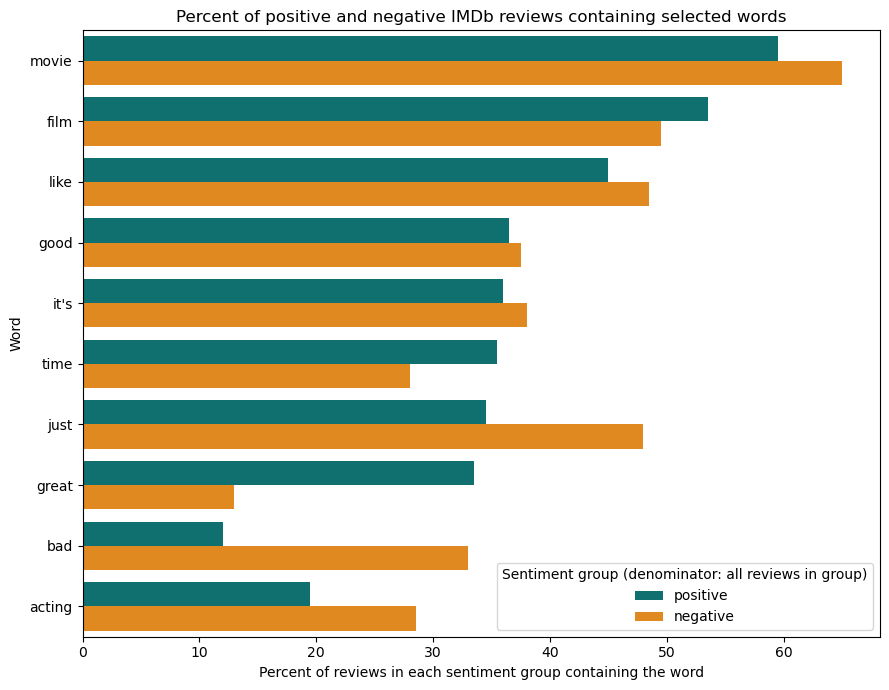

sentiment  word  count  reviews_with_word  percent_reviews
 positive great    103                 67             33.5
 positive   bad     33                 24             12.0
 negative great     30                 26             13.0
 negative   bad    113                 66             33.0


In [10]:
# Create Figure 1 with descriptive titles, readable labels, and clear units or denominators.
review_counts = reviews_df.groupby('sentiment')['review_id'].nunique()

frequency_df = words_df.groupby(['sentiment', 'word']).agg(count=('word', 'size'), reviews_with_word=('review_id', 'nunique')).reset_index()
frequency_df['percent_reviews'] = (100 * frequency_df['reviews_with_word'] / frequency_df['sentiment'].map(review_counts))

selected_words = []
for label in label_order:
    top = frequency_df.loc[frequency_df['sentiment'].eq(label)].nlargest(8, 'percent_reviews')['word']
    selected_words.extend(word for word in top if word not in selected_words)

comparison = frequency_df.set_index(['sentiment', 'word']).reindex(
    pd.MultiIndex.from_product([label_order, selected_words], names=['sentiment', 'word']), fill_value=0).reset_index()

plt.figure(figsize=(9, 7))
sns.barplot(data=comparison, x='percent_reviews', y='word', hue='sentiment', order=selected_words, hue_order=label_order, palette={'positive': 'teal', 'negative': 'darkorange'})
plt.xlabel('Percent of reviews in each sentiment group containing the word')
plt.ylabel('Word')
plt.title('Percent of positive and negative IMDb reviews containing selected words')
plt.legend(title='Sentiment group (denominator: all reviews in group)')
plt.tight_layout()
plt.show()

print(comparison.loc[comparison['word'].isin(['great', 'bad'])].to_string(index=False))

**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer: The bar chart shows that a few words separate the groups. "great" appears in 33.50% of positive reviews (67 of 200) and 13.00% of negative reviews (26 of 200), while "bad" goes the other way, at 12.00% of positive reviews (24 of 200) and 33.00% of negative reviews (66 of 200). Because this sample includes reviews of films, games, and shows, words such as "movie" and "film" appear in both groups and are not useful for separating sentiment. The evaluative words do lean in the expected direction.

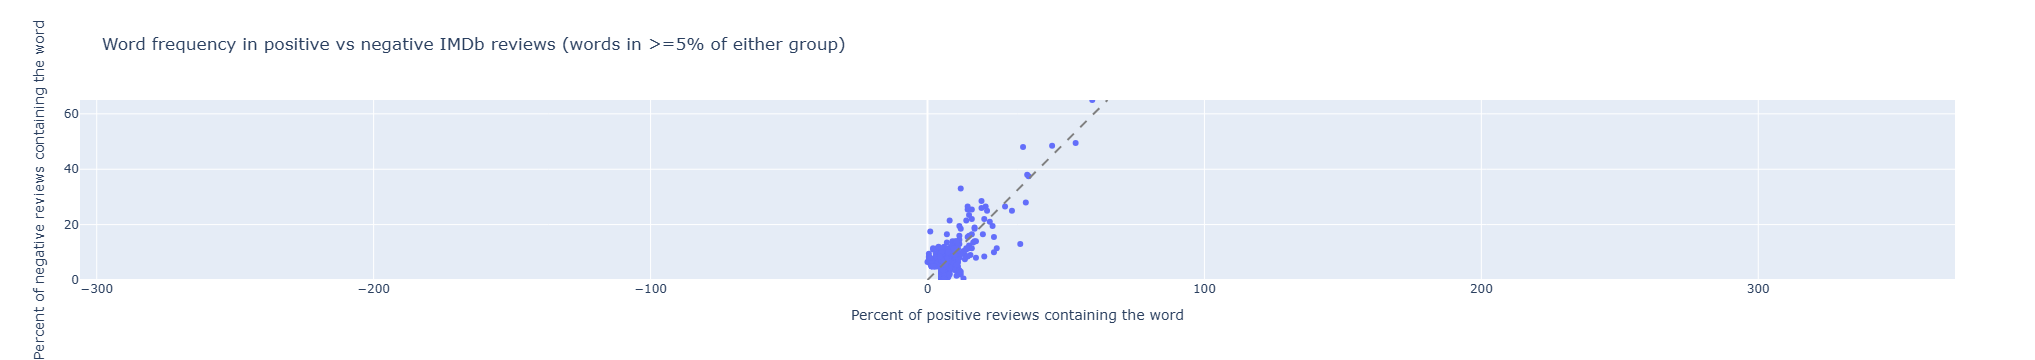

 word  percent_negative  percent_positive
  bad              33.0              12.0
great              13.0              33.5
worst              17.5               1.0


In [11]:
# Create Figure 2 using a different chart type to answer the same question.
# Label any transformation or display threshold.

scatter_df = frequency_df.pivot(index='word', columns='sentiment', values='percent_reviews').fillna(0).reset_index()
scatter_df = scatter_df.rename(columns={'positive': 'percent_positive', 'negative': 'percent_negative'})

display_scatter_df = scatter_df[(scatter_df['percent_positive'] >= 5) | (scatter_df['percent_negative'] >= 5)].copy()

max_percent = max(display_scatter_df['percent_positive'].max(), display_scatter_df['percent_negative'].max())

fig = px.scatter(
    display_scatter_df,
    x='percent_positive',
    y='percent_negative',
    hover_name='word',
    labels={
        'percent_positive': 'Percent of positive reviews containing the word',
        'percent_negative': 'Percent of negative reviews containing the word'
    },
    title='Word frequency in positive vs negative IMDb reviews (words in >=5% of either group)')
fig.add_shape(type='line', x0=0, y0=0, x1=max_percent, y1=max_percent, line=dict(dash='dash', color='gray'))
fig.update_yaxes(range=[0, max_percent], scaleanchor='x', scaleratio=1)
fig.update_xaxes(range=[0, max_percent])
fig.show()

print(display_scatter_df.loc[display_scatter_df['word'].isin(['great', 'bad', 'worst'])].to_string(index=False))

**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer: The scatter plot adds many more words than the bar chart. "great" is at 33.50% positive and 13.00% negative, so it sits below the equal line, while "bad" is at 12.00% positive and 33.00% negative, so it sits above the line. "worst" is even more one-sided, at 1.00% of positive reviews and 17.50% of negative reviews. The 5% threshold keeps the plot readable but leaves out rarer words.

### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [12]:
# Verify two plotted values and their denominators, if applicable.
# Display a few work-appropriate original texts to check meaning in context.

for word in ['great', 'bad']:
    for label in label_order:
        docs = reviews_df.loc[reviews_df['sentiment'].eq(label), 'review_id'].nunique()
        docs_with = words_df.loc[
            (words_df['sentiment'].eq(label)) & (words_df['word'].eq(word)), 'review_id'
        ].nunique()
        pct = 100 * docs_with / docs
        print(f"{word!r} in {label_titles[label]}: {docs_with} of {docs} reviews = {pct:.2f}%")
    print()

for word, label in [('great', 'positive'), ('bad', 'negative')]:
    sample_ids = words_df.loc[
        (words_df['sentiment'].eq(label)) & (words_df['word'].eq(word)), 'review_id'
    ].drop_duplicates().head(2)
    print(f"--- Sample original {label_titles[label]} containing '{word}' ---")
    for rid in sample_ids:
        text = reviews_df.loc[reviews_df['review_id'].eq(rid), 'original_text'].iloc[0]
        print(f"review_id={rid}: {text[:300]}...")
        print()


'great' in Positive reviews: 67 of 200 reviews = 33.50%
'great' in Negative reviews: 26 of 200 reviews = 13.00%

'bad' in Positive reviews: 24 of 200 reviews = 12.00%
'bad' in Negative reviews: 66 of 200 reviews = 33.00%

--- Sample original Positive reviews containing 'great' ---
review_id=1: What is worth mentioning that is omitted in the other reviews I have read here, is the subtext of how the law shaped the lives and behaviour of gays in the era portrayed in the film. While Courtenay's character is evidently gay, he is not the only one: the often talked about Mr. Davenport-Scott is t...

review_id=2: This is the French and Belgians doing what they do best. It's quirky, visually inventive, exhilarating and emotionally challenging storytelling. Director Jaco van Dormael takes us into the world of Georges, a Down's Syndrome sufferer and his quest for a meaningful relationship with someone, just any...

--- Sample original Negative reviews containing 'bad' ---
review_id=210: let me ge

**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer: I checked "great" and "bad" against the token table. "great" is in 67 of 200 positive reviews (33.50%) and 26 of 200 negative reviews (13.00%). "bad" is in 24 of 200 positive reviews (12.00%) and 66 of 200 negative reviews (33.00%). Both match the figures. The original reviews show that a word can appear with contrast or other nearby wording, so word presence alone does not prove the whole review is positive or negative. I did not make a correction.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer: My question was how vocabulary differs between positive and negative IMDb reviews in this sample. The evidence shows that "great" is more common in positive reviews (33.50% versus 13.00%) and "bad" is more common in negative reviews (33.00% versus 12.00%). The scatter plot shows the same split across many words, with "worst" at 1.00% of positive reviews and 17.50% of negative reviews. This matches my prediction, although common words such as "movie" and "like" appear in both groups. That makes sense for a mixed sample of entertainment reviews. The figures show word-use patterns, not the full meaning of each review.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: One limitation is that the sample was screened for stronger profanity and restricted to 400 reviews, so it is not every IMDb review and the screen may change word frequencies. Another is that simple tokens lose context, negation, and phrases. The bar chart makes selected-word comparisons clear but shows only a few words. The scatter plot shows many words and the overall split, but overlapping points and the 5% threshold hide rarer words and some exact values. Together they give useful complementary evidence, but neither figure explains why a word appears in a review.

## Investigation 2: Your dataset and research question


### Step 1: Question

Ask one focused question about the text. Identify the documents, groups if relevant, and the vocabulary or text-derived feature you will examine. Record a prediction before producing figures.


**What is your research question, and what do you predict? Why is text analysis useful for answering it?**

Your answer: My question is how vocabulary and passage length differ between detective-fiction passages from *The Adventures of Sherlock Holmes* and adventure-fiction passages from *The Call of the Wild*. I expect the detective passages to contain more words connected with people, conversation, and investigation. I expect the adventure passages to contain more words connected with animals, wilderness, travel, and survival. I also expect the adventure passages to be longer. Text analysis lets me compare those patterns across all the passages in the sample instead of judging a few excerpts.

### Step 2: Data

Document the source and explain what one row represents. Load a fixed copy, inspect the first and last rows and shape, use `.info()` to inspect the data storage types and non-missing values, and count missing values. Identify blank text separately from missing values.


**Give the dataset title, publisher, direct source URL, feature-definition reference, and access date. Identify your saved files.**

Your answer: The dataset is a passage-level sample I assembled from two Project Gutenberg books: *The Adventures of Sherlock Holmes* by Arthur Conan Doyle (eBook 1661) and *The Call of the Wild* by Jack London (eBook 215). I used the plain-text links at https://raw.githubusercontent.com/GITenberg/The-Adventures-of-Sherlock-Holmes_1661/master/1661.txt and https://raw.githubusercontent.com/GITenberg/The-Call-of-the-Wild_215/master/215.txt. The feature definitions are the columns I saved in `data/gutenberg_passages.csv`: `document_id`, `book`, `author`, `group`, and `passage`. The access date is 2026-11-16.

**What does one row represent? What texts and groups are covered, and how were they collected? How did you check that the language and displayed examples are work appropriate?**

Your answer: One row represents one passage, not one book and not one word. The passages are paragraph-length blocks from the two books, with `group` labeling Detective fiction or Adventure fiction. I removed Gutenberg header and footer material where present, took qualifying paragraph-length passages in book order, and saved the fixed CSV. I checked sample passages from the file and the original-text examples used later. Both books are classic public-domain literature, and I avoided displaying anything unsuitable for a classroom presentation.

In [13]:
# Read dataset 2 from a relative path into a descriptive DataFrame ending in _df.
passages_df = pd.read_csv("data/gutenberg_passages.csv")

In [14]:
# Display .head(), .tail(), and .shape in separate cells. Add cells as needed.
passages_df.head()

,document_id,book,author,group,passage
0,sherlock_001,The Adventures of Sherlock Holmes,Arthur Conan Doyle,Detective fiction,To Sherlock Holmes she is always THE woman. I ...
1,sherlock_002,The Adventures of Sherlock Holmes,Arthur Conan Doyle,Detective fiction,I had seen little of Holmes lately. My marriag...
2,sherlock_003,The Adventures of Sherlock Holmes,Arthur Conan Doyle,Detective fiction,"One night--it was on the twentieth of March, 1..."
3,sherlock_004,The Adventures of Sherlock Holmes,Arthur Conan Doyle,Detective fiction,His manner was not effusive. It seldom was; bu...
4,sherlock_005,The Adventures of Sherlock Holmes,Arthur Conan Doyle,Detective fiction,"""My dear Holmes,"" said I, ""this is too much. Y..."


In [15]:
passages_df.tail()

,document_id,book,author,group,passage
295,wild_146,The Call of the Wild,Jack London,Adventure fiction,"As it was with Buck, so was it with his mates...."
296,wild_147,The Call of the Wild,Jack London,Adventure fiction,"There came a day when Billee, the good-natured..."
297,wild_148,The Call of the Wild,Jack London,Adventure fiction,"It was beautiful spring weather, but neither d..."
298,wild_149,The Call of the Wild,Jack London,Adventure fiction,From every hill slope came the trickle of runn...
299,wild_150,The Call of the Wild,Jack London,Adventure fiction,"With the dogs falling, Mercedes weeping and ri..."


In [16]:
passages_df.shape

(300, 5)

In [17]:
# Use .info() to inspect the data storage types and non-missing values.
# Count missing values in every feature and identify blank text.
passages_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   document_id  300 non-null    object
 1   book         300 non-null    object
 2   author       300 non-null    object
 3   group        300 non-null    object
 4   passage      300 non-null    object
dtypes: object(5)
memory usage: 11.8+ KB


In [18]:
passages_df.isnull().sum()

document_id    0
book           0
author         0
group          0
passage        0
dtype: int64

In [19]:
# Identify blank passage text separately from missing values.
int((passages_df['passage'].astype(str).str.strip() == '').sum())

0

**Complete the table for every feature used in the question, preparation, or figures. Add rows as needed.**

| Feature | Meaning and units or codes | Feature type | Data storage type | Missing values |
| --- | --- | --- | --- | --- |
| `document_id` | Unique identifier for each passage; not a measurement. | categorical | object | 0 |
| `book` | Source book title. | categorical | object | 0 |
| `author` | Source book author. | categorical | object | 0 |
| `group` | Genre label: `Detective fiction` or `Adventure fiction`. | categorical | object | 0 |
| `passage` | Original passage text, in words. | text | object | 0 missing and 0 blank text values |
| `length_words` | Passage length in words (whitespace-separated tokens). | quantitative | int64 | 0 (derived from `passage`) |

Use text, quantitative, categorical, or temporal for feature type.

Your answer: I use `passage` for the vocabulary and length analysis and `group` for the comparison. I keep `document_id`, `book`, and `author` to identify each passage and check context.

**Which records and features will you use? Explain your groups, sampling, missing or blank text, duplicates, content screening, and text-preparation decisions, including stopwords.**

Your answer: I'll use `document_id`, `group`, and `passage` from `passages_df`; `book` and `author` stay in the table for documentation. The two groups are Detective fiction and Adventure fiction. The passages were assembled into a fixed CSV before this notebook, with document IDs preserving book and passage order. I checked missing and blank passage text and would remove blanks if present. I keep the original text, lowercase a prepared copy, extract words with `r"\b[a-z']+\b"`, remove `ENGLISH_STOP_WORDS` plus an empty `additional_stopwords` list, and drop words shorter than 3 characters. I also calculate `length_words` from the original passage. The same preparation applies to both groups.

In [20]:
# Preserve original text and document IDs. Prepare text and calculated features.
# Report original and retained row counts and the number of documents in each group.
group_order = ['Detective fiction', 'Adventure fiction']

passages_df['original_text'] = passages_df['passage']
passages_df['document_id'] = passages_df['document_id'].astype(str)

print('Original rows:', len(passages_df))
print('Retained rows:', len(passages_df))
print('Documents in each group:')
print(passages_df['group'].value_counts().reindex(group_order))

passages_df['length_words'] = passages_df['passage'].astype(str).str.split().str.len()

passages_df['prepared_text'] = passages_df['passage'].astype(str).str.lower()
passages_df['words'] = passages_df['prepared_text'].str.findall(r"\b[a-z']+\b")
tokens_df = passages_df[['document_id', 'group', 'words']].explode('words')
tokens_df = tokens_df.rename(columns={'words': 'word'})

additional_stopwords = []
stopwords = set(ENGLISH_STOP_WORDS).union(additional_stopwords)

tokens_df = tokens_df.loc[tokens_df['word'].notna() & ~tokens_df['word'].isin(stopwords) & (tokens_df['word'].str.len() >= 3)].copy()

print('Retained word tokens after stopword/length filtering:', len(tokens_df))

Original rows: 300
Retained rows: 300
Documents in each group:
group
Detective fiction    150
Adventure fiction    150
Name: count, dtype: int64
Retained word tokens after stopword/length filtering: 13471


**How many records were removed from the dataset? Explain why, and state what one row represents in each analysis table.**

Your answer: No records were removed from the saved analysis file; all 300 passages were retained, with 150 per group. The file has one row per passage. In `tokens_df`, one row is one retained word occurrence, so a passage can appear many times.

### Step 3: Evidence

Create two different figure types that answer this same question. At least one must support a numerical comparison. Use consistent preparation and explain any difference in the records or words displayed.


**Which two chart types will you use, and what should each make easier to answer? Specify what positions, colors, and sizes represent and define any percentage denominator.**

Your answer: I will use a grouped bar chart and a box plot. In the bar chart, y positions are selected words, x positions are the percent of passages containing each word, and color separates the two groups. The denominator is all 150 passages in that group, counting each passage once per word. The box plot puts group on the category axis and passage length in words on the y-axis; each box shows the median, quartiles, and possible outliers. The bar chart answers which words are more common within each group, and the box plot answers whether passage lengths differ.

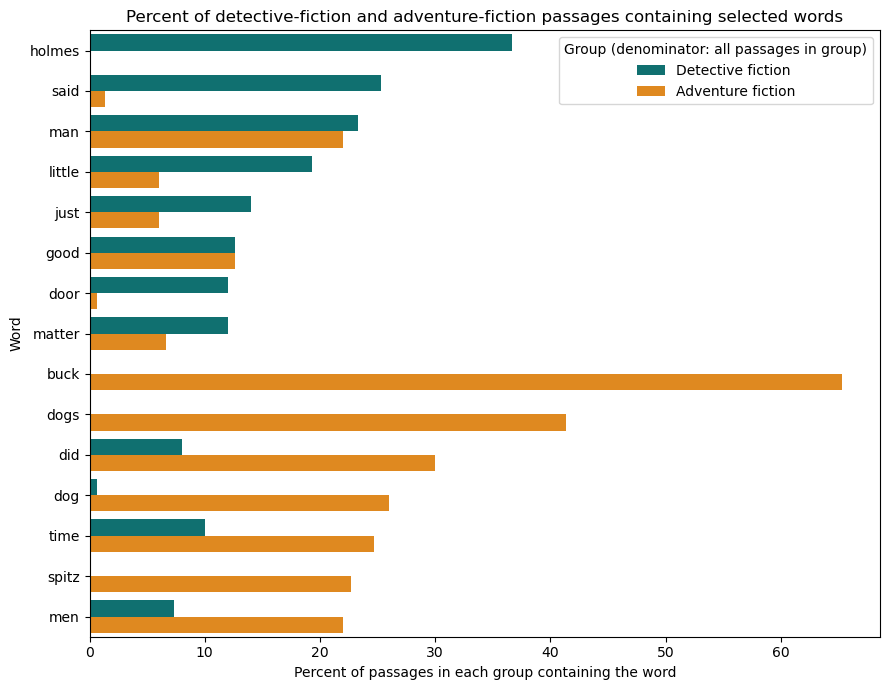

            group   word  count  documents_with_word  percent_documents
Detective fiction holmes     63                   55          36.666667
Detective fiction   door     20                   18          12.000000
Detective fiction   buck      0                    0           0.000000
Detective fiction   dogs      0                    0           0.000000
Adventure fiction holmes      0                    0           0.000000
Adventure fiction   door      1                    1           0.666667
Adventure fiction   buck    173                   98          65.333333
Adventure fiction   dogs     94                   62          41.333333


In [21]:
# Create Figure 1 with descriptive titles, readable labels, and clear units or denominators.
group_sizes = passages_df.groupby('group')['document_id'].nunique()

word_counts = tokens_df.groupby(['group', 'word']).agg(count=('word', 'size'), documents_with_word=('document_id', 'nunique')).reset_index()
word_counts['percent_documents'] = (100 * word_counts['documents_with_word'] / word_counts['group'].map(group_sizes))

selected_words_2 = []
for group in group_order:
    top = word_counts.loc[word_counts['group'].eq(group)].nlargest(8, 'percent_documents')['word']
    selected_words_2.extend(word for word in top if word not in selected_words_2)

comparison_2 = word_counts.set_index(['group', 'word']).reindex(pd.MultiIndex.from_product([group_order, selected_words_2], names=['group', 'word']), fill_value=0).reset_index()

plt.figure(figsize=(9, 7))
sns.barplot(
    data=comparison_2, x='percent_documents', y='word', hue='group',
    order=selected_words_2, hue_order=group_order,
    palette={'Detective fiction': 'teal', 'Adventure fiction': 'darkorange'}
)
plt.xlabel('Percent of passages in each group containing the word')
plt.ylabel('Word')
plt.title('Percent of detective-fiction and adventure-fiction passages containing selected words')
plt.legend(title='Group (denominator: all passages in group)')
plt.tight_layout()
plt.show()


print(comparison_2.loc[comparison_2['word'].isin(['holmes', 'buck', 'door', 'dogs'])].to_string(index=False))

**What does Figure 1 show? Describe a pattern and record at least one supporting value, identifying its word or text feature, group, and units.**

Your answer: The bar chart shows clear separation between the two books. "holmes" appears in 36.67% of detective passages (55 of 150) and 0.00% of adventure passages, while "buck" appears in 0.00% of detective passages and 65.33% of adventure passages (98 of 150). Words like "said" and "door" also lean detective, and "dogs" and "spitz" lean adventure. This supports my prediction that vocabulary reflects the different people, settings, and animal focus of the two books.

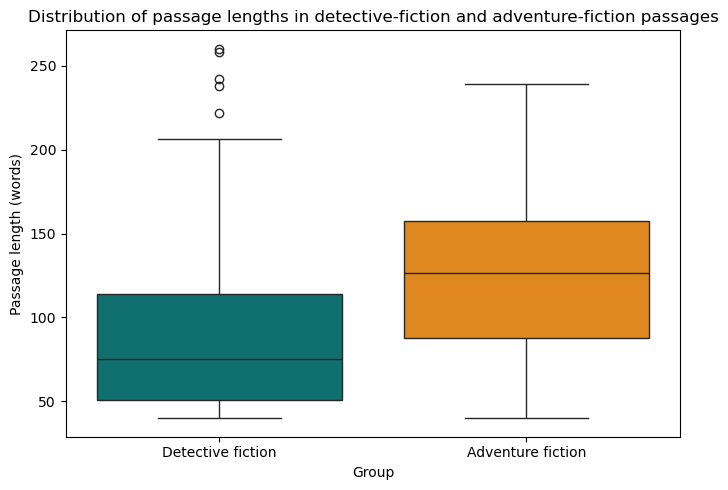

group
Detective fiction     75.5
Adventure fiction    126.5
Name: length_words, dtype: float64


In [22]:
# Create Figure 2 using a different chart type to answer the same question.
# Label any transformation or display threshold.
plt.figure(figsize=(7, 5))
sns.boxplot(
    data=passages_df, x='group', y='length_words', hue='group',
    order=group_order, hue_order=group_order, legend=False,
    palette={'Detective fiction': 'teal', 'Adventure fiction': 'darkorange'}
)
plt.xlabel('Group')
plt.ylabel('Passage length (words)')
plt.title('Distribution of passage lengths in detective-fiction and adventure-fiction passages')
plt.tight_layout()
plt.show()

print(passages_df.groupby('group')['length_words'].median().reindex(group_order))

**What does Figure 2 add? Record at least one supporting value and compare its message with Figure 1.**

Your answer: The box plot adds length evidence that the word chart cannot show. Detective passages have a median of 75.5 words, while adventure passages have a median of 126.5 words. The adventure box is also shifted higher overall, which matches my prediction that those passages would be longer. The word chart tells me which vocabulary separates the groups; the box plot tells me about the amount of text in each passage.

### Step 4: Check

Verify at least two plotted values against records or calculated summaries. Read a few original texts containing a selected word or illustrating a pattern, using the lecture's sample function or your own code. For grouped comparisons, check examples from each relevant group when matches exist. Explain whether context supports your interpretation. Do not repeat the initial missing-value count.


In [23]:
# Verify two plotted values and their denominators, if applicable.
# Display a few work-appropriate original texts to check meaning in context.
for word in ['holmes', 'buck']:
    for group in group_order:
        docs = passages_df.loc[passages_df['group'].eq(group), 'document_id'].nunique()
        docs_with = tokens_df.loc[
            (tokens_df['group'].eq(group)) & (tokens_df['word'].eq(word)), 'document_id'
        ].nunique()
        pct = 100 * docs_with / docs
        print(f"{word!r} in {group}: {docs_with} of {docs} passages = {pct:.2f}%")
    print()

print('Median passage length (words) by group:')
print(passages_df.groupby('group')['length_words'].median().reindex(group_order))
print()

for word, group in [('holmes', group_order[0]), ('buck', group_order[1])]:
    sample_ids = tokens_df.loc[
        (tokens_df['group'].eq(group)) & (tokens_df['word'].eq(word)), 'document_id'
    ].drop_duplicates().head(1)
    if len(sample_ids) == 0:
        continue
    did = sample_ids.iloc[0]
    row = passages_df.loc[passages_df['document_id'].eq(did)].iloc[0]
    print(f"--- Sample {group} passage containing '{word}' (document_id={did}, {row['book']}) ---")
    print(str(row['original_text'])[:350] + '...')
    print()

'holmes' in Detective fiction: 55 of 150 passages = 36.67%
'holmes' in Adventure fiction: 0 of 150 passages = 0.00%

'buck' in Detective fiction: 0 of 150 passages = 0.00%
'buck' in Adventure fiction: 98 of 150 passages = 65.33%

Median passage length (words) by group:
group
Detective fiction     75.5
Adventure fiction    126.5
Name: length_words, dtype: float64

--- Sample Detective fiction passage containing 'holmes' (document_id=sherlock_001, The Adventures of Sherlock Holmes) ---
To Sherlock Holmes she is always THE woman. I have seldom heard him mention her under any other name. In his eyes she eclipses and predominates the whole of her sex. It was not that he felt any emotion akin to love for Irene Adler. All emotions, and that one particularly, were abhorrent to his cold, precise but admirably balanced mind. He was, I ta...

--- Sample Adventure fiction passage containing 'buck' (document_id=wild_002, The Call of the Wild) ---
Buck did not read the newspapers, or he would have k

**Which two values did you check, and did they agree? What did the original text reveal that the figures could not? Describe any correction you made.**

Your answer: I checked "holmes" and "buck" against the passage table. "holmes" appears in 55 of 150 detective passages (36.67%) and 0 of 150 adventure passages. "buck" appears in 0 of 150 detective passages and 98 of 150 adventure passages (65.33%). Both match the figure. The median lengths also match the box plot: 75.5 words for detective passages and 126.5 words for adventure passages. Reading the original passages showed that these words are tied to the main character and setting, which the counts alone cannot explain. I did not make a correction.

### Step 5: Conclusion

Restate your research question, then answer it using evidence from **both** figures. Include numerical values with clear units or denominators and explain whether the evidence supports your prediction.


**Restate your question and write your conclusion.**

Your answer: My question was how vocabulary and passage length differ between the two selected fiction samples. The detective passages were more likely to contain "holmes" (36.67% versus 0.00%) and "door" (12.00% versus 0.67%), while the adventure passages were more likely to contain "buck" (65.33% versus 0.00%) and "dogs" (41.33% versus 0.00%). The box plot showed that adventure passages were longer, with medians of 126.5 and 75.5 words. These results match my prediction. They apply to these two books and these passage boundaries, not to all fiction.

### Step 6: Limitation

Identify **two limitations of your analysis**. Then explain which aspects of your question are easier or harder to answer from each figure.


**What are two limitations, and how do the strengths and weaknesses of your figures affect the answer?**

Your answer: One limitation is that each group comes from one book, so the differences may reflect the authors or selected passages rather than genre in general. Some of the strongest separating words are book-specific proper names, such as "holmes" and "buck." Those words help distinguish these two books, but they are not general evidence about detective fiction or adventure fiction as a whole. Another is that passage boundaries and simple token preparation affect both word percentages and length. The bar chart makes exact word comparisons clear but shows only selected words. The box plot shows length distribution well but says nothing about content. Together they answer different parts of the question, but neither shows context or supports a causal claim.

## AI-use reflection


**Did you use AI? If so, describe one suggestion you checked against your source, code, or output and what you accepted, modified, or rejected. If not, state that you did not use it.**

Your answer: Yes. I used AI to help organize the notebook, draft wording, and prepare/check the screened IMDb sample. One suggestion I checked was the keyword screen for stronger profanity before saving the fixed CSV. I reviewed sample records and the displayed excerpts to make sure the examples used in the notebook stayed work and class appropriate, and I kept the screen while noting that it can affect word frequencies. I also checked the suggestion to calculate "percent of documents containing a word" with `nunique()` divided by group size against the lecture example, and I kept it after confirming that the denominator was all documents in that group.

## Submission checklist

- Include two distinct text datasets and document their sources, feature definitions, collection context, and access dates.
- Review the datasets and displayed language for work appropriateness; document any screening and its effects.
- Ask one research question per dataset and complete all six steps for each question.
- Complete both feature tables and every written response.
- Include four finished figures: two different chart types per question, with at least one numerical comparison per pair.
- Explain text preparation, stopwords, filtering, missing or blank text, duplicates, group sizes, and row counts.
- Define what is counted and the denominator of every percentage.
- Check two plotted values and original text context for each investigation.
- Restate each question in its conclusion and cite evidence from both figures.
- Identify two limitations per investigation and compare what the displays reveal or obscure.
- Include your data files and any preparation code using relative paths. Complete the AI-use reflection, restart the kernel, and run cells in order before submitting.
